### Autocomplete and Autocorrect Data Analytics
##### Objective: Analyze the efficiency and accuracy of autocomplete and autocorrect algorithms using NLP techniques. Implement and compare multiple approaches for text prediction and spelling correction on a real text dataset.

In [1]:
import re
from bs4 import BeautifulSoup

path = r"C:\Users\HP\OneDrive\Documents\OASIS INFOBYTE\Level 2 - Task 5\pg1342-images.html"

with open(path, "r", encoding="utf-8") as f:
    soup = BeautifulSoup(f, "html.parser")

raw_text = soup.get_text(separator=' ')

# Trim the Gutenberg header/footer
start = raw_text.find('START OF THE PROJECT GUTENBERG EBOOK')
end = raw_text.find('END OF THE PROJECT GUTENBERG EBOOK')
corpus = raw_text[start:end] if end != -1 else raw_text[start:]

print('Characters:', len(corpus))
print('Approx. words:', len(corpus.split()))
print(corpus[:500])

Characters: 723995
Approx. words: 127877
START OF THE PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE *** 
 
 
 
 
 PREFACE. 
 List of Illustrations. 
 Chapter: I.,  
 II.,  
 III.,  
 IV.,  
 V.,  
 VI.,  
 VII.,  
 VIII.,  
 IX.,  
 X.,  
 XI.,  
 XII.,  
 XIII.,  
 XIV.,  
 XV.,  
 XVI.,  
 XVII.,  
 XVIII.,  
 XIX.,  
 XX.,  
 XXI.,  
 XXII.,  
 XXIII.,  
 XXIV.,  
 XXV.,  
 XXVI.,  
 XXVII.,  
 XXVIII.,  
 XXIX.,  
 XXX.,  
 XXXI.,  
 XXXII.,  
 XXXIII.,  
 XXXIV.,  
 XXXV.,  
 XXXVI.,  
 XXXVII.,  
 XXXVIII.,  
 XXXIX.,  
 XL.,  
 XL


In [2]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# 1. Cut off the table of contents: start at the novel's first sentence
start = corpus.find("It is a truth universally acknowledged")
corpus_cleaned = corpus[start:]
corpus_cleaned = re.sub(r'Chapter\s+[IVXLC]+\.?', '', corpus_cleaned)
print(corpus_cleaned[:300])

# 2. Tokenize + lowercase + remove punctuation/numbers
tokens = word_tokenize(corpus_cleaned.lower())
tokens_all = [t for t in tokens if t.isalpha()]  # keeps stopwords (for auto complete)

# 3. Stopword removal (for frequency analysis)
stop_words = set(stopwords.words('english'))
tokens_nostop = [t for t in tokens_all if t not in stop_words]

print('Raw tokens: ', len(tokens))
print('After punctuation: ', len(tokens_all))
print('After stopwords: ', len(tokens_nostop))
print('Unique words: ', len(set(tokens_all)))

 
Raw tokens:  0
After punctuation:  0
After stopwords:  0
Unique words:  0


[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


In [3]:
print(start)
print(len(corpus_cleaned))

-1
1


In [4]:
# Collapse all whitespace/newlines into single spaces
corpus_norm = re.sub(r"\s+", " ", corpus)

# Find the novel's opening (case-insensitive), skipping the table of contents
matches = [m.start() for m in re.finditer(r"is a truth universally acknowledged", corpus_norm, re.I)]
print("Matches found at:", matches)

start = matches[-1] if matches else 0   
corpus_cleaned = "it " + corpus_norm[start:]

# Remove chapter headings and the page captions/copyright notes
corpus_cleaned = re.sub(r"Chapter\s+[IVXLC]+\.?", " ", corpus_cleaned)
corpus_cleaned = re.sub(r"\[Copyright[^\]]*\]", " ", corpus_cleaned)
corpus_cleaned = re.sub(r"\[Illustration[^]]*\]", " ", corpus_cleaned)

print(len(corpus_cleaned))
print(corpus_cleaned[:300])

Matches found at: [28936]
688101
it is a truth universally acknowledged, that a single man in possession of a good fortune must be in want of a wife. However little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed in the minds of the surrounding families, that he is


In [5]:
tokens = word_tokenize(corpus_cleaned.lower())
tokens_all = [t for t in tokens if t.isalpha()]
tokens_nostop = [t for t in tokens_all if t not in stop_words]

print('Raw tokens:       ', len(tokens))
print('After punctuation:', len(tokens_all))
print('After stopwords:  ', len(tokens_nostop))
print('Unique words:     ', len(set(tokens_all)))

Raw tokens:        145477
After punctuation: 120320
After stopwords:   52761
Unique words:      6214


In [6]:
# Autocompleter (frequency-based n-gram model)
from collections import defaultdict, Counter

bigram_model = defaultdict(Counter)
trigram_model = defaultdict(Counter)

for w1, w2 in zip(tokens_all, tokens_all[1:]):
    bigram_model[w1][w2] += 1

for w1, w2, w3 in zip(tokens_all, tokens_all[1:], tokens_all[2:]):
    trigram_model[(w1, w2)][w3] += 1

def autocomplete(prefix, k=3):
    words = prefix.lower().split()
    if len(words) >=2 and tuple(words[-2:]) in trigram_model:
        counts = trigram_model[tuple(words[-2:])]     # trigram
    elif words and words[-1] in bigram_model:
        counts = bigram_model[words[-1]]              # backoff to bigram
    else:
        return []
    return [w for w, _ in counts.most_common(k)]

print("Bigram contexts: ", len(bigram_model))
print("Trigram contexts: ", len(trigram_model))
print(autocomplete("mr"))
print(autocomplete("miss elizabeth"))

Bigram contexts:  6214
Trigram contexts:  53532
['darcy', 'collins', 'bennet']
['bennet', 'that', 'miss']


In [7]:
# Test prefixes
import pandas as pd

test_prefixes = [
    "mr", "mrs", "miss elizabeth", "i am", "she was",
     "of the", "it is", "my dear", "lady catherine", "you must"
]

results = []
for p in test_prefixes:
    preds = autocomplete(p, k=3)
    results.append({
        "Prefix": p,
        "Prediction 1": preds[0] if len(preds) > 0 else "-",
        "Prediction 2": preds[1] if len(preds) > 1 else "-",
        "Prediction 3": preds[2] if len(preds) > 2 else "-"
    })

autocomplete_df = pd.DataFrame(results)
autocomplete_df

,Prefix,Prediction 1,Prediction 2,Prediction 3
0,mr,darcy,collins,bennet
1,mrs,bennet,collins,wickham
2,miss elizabeth,bennet,that,miss
3,i am,sure,not,afraid
4,she was,not,in,a
5,of the,family,room,world
6,it is,a,not,very
7,my dear,lizzy,miss,aunt
8,lady catherine,s,de,and
9,you must,be,not,know


In [8]:
from collections import Counter

# Dictionary from the corpus (drop stray single letters except 'a' and 'i')
word_freq = Counter(tokens_all)
vocab = {w: c for w, c in word_freq.items() if len(w) > 1 or w in ("a", "i")}
print("Dictionary size:", len(vocab))

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        curr = [i]
        for j, cb in enumerate(b, 1):
            cost = 0 if ca == cb else 1
            curr.append(min(prev[j] + 1,        # deletion
                            curr[j - 1] + 1,    # insertion
                            prev[j - 1] + cost))  # substitution
        prev = curr
    return prev[-1]

def autocorrect(word, max_dict=2):
    word = word.lower()
    if word in vocab:
        return word
    best, best_dict = word, max_dict + 1
    for cand, freq in vocab.items():
        if abs(len(cand) - len(word)) > max_dict:
            continue
        d = levenshtein(word, cand)
        if d < best_dict or (d == best_dict and freq > vocab.get(best, 0)):
            best, best_dict = cand, d
    return best if best_dict <= max_dict else word

for w in ["elizabth", "darcey", "beautful", "recieve", "gentelman"]:
    print(w, "->", autocorrect(w))

Dictionary size: 6206
elizabth -> elizabeth
darcey -> darcy
beautful -> beautiful
recieve -> relieve
gentelman -> gentleman


In [9]:
# Test autocorrect on 20+ misspelled words and measure accuracy
test_pairs = [
    ('elizabth', 'elizabeth'), ('darcey', 'darcy'), ('wickam', 'wickham'),
    ('collinz', 'collins'), ('netherfeild', 'netherfield'),
    ('beautful', 'beautiful'), ('dauhgter', 'daughter'), ('mornning', 'morning'),
    ('sistr', 'sister'), ('freind', 'friend'), ('toghter', 'together'),
    ('hapiness', 'happiness'), ('affectoin', 'affection'), 
    ('acquaintence', 'acquaintance'), ('handsom', 'handsome'),
    ('charcter', 'character'), ('opinon', 'opinion'), ('mariage', 'marriage'),
    ('familly', 'family'), ('pleasre', 'pleasure'), ('dispostion', 'disposition'),
    ('gentelman', 'gentleman'), ('recieve', 'receive')
]

# Sanity check: every target word must exist in the dictionary
print('Missing from vocab:', [c for _, c in test_pairs if c not in vocab])

rows = []
for wrong, correct in test_pairs:
    fixed = autocorrect(wrong)
    rows.append({'Misspelled': wrong, 'Expected': correct,
                 'Corrected': fixed, 'Correct?': fixed == correct})

autocorrect_df = pd.DataFrame(rows)
display(autocorrect_df)

accuracy = autocorrect_df['Correct?'].mean()
print(f'Correct: {autocorrect_df['Correct?'].sum()}/{len(autocorrect_df)}')
print(f'Autocorrect accuracy: {accuracy:.2%}')

Missing from vocab: []


,Misspelled,Expected,Corrected,Correct?
0,elizabth,elizabeth,elizabeth,True
1,darcey,darcy,darcy,True
2,wickam,wickham,wickham,True
3,collinz,collins,collins,True
4,netherfeild,netherfield,netherfield,True
5,beautful,beautiful,beautiful,True
6,dauhgter,daughter,daughter,True
7,mornning,morning,morning,True
8,sistr,sister,sister,True
9,freind,friend,friend,True


Correct: 22/23
Autocorrect accuracy: 95.65%


In [10]:
# Precision and recall for both
# Autocorrect 
## TP: a misspelled word corrected to the right word
## FP: a change that's wrong, whether a bad correction or a correct word that got altered
## FN: a misspelled word that wasn't fixed correctly

ac_tp = ac_fp = ac_fn = 0

for wrong, correct in test_pairs:
    out = autocorrect(wrong)
    if out == correct:
        ac_tp += 1
    else:
        ac_fn += 1
        if out != wrong:
            ac_fp += 1

# Correct words should be left alone 
for _, correct in test_pairs:
    if autocorrect(correct) != correct:
        ac_fp += 1

ac_precision = ac_tp / (ac_tp + ac_fp)
ac_recall = ac_tp / (ac_tp + ac_fn)
print(f'TP={ac_tp}  FP={ac_fp}  FN={ac_fn}')
print(f'Autocorrect precision: {ac_precision:.2%}')
print(f'Autocorrect recall: {ac_recall:.2%}')

TP=22  FP=1  FN=1
Autocorrect precision: 95.65%
Autocorrect recall: 95.65%


In [11]:
# Autocomplete

split = int(len(tokens_all) * 0.8)
train, test = tokens_all[:split], tokens_all[split:]

bi_tr, tri_tr = defaultdict(Counter), defaultdict(Counter)
for a, b in zip(train, train[1:]):
    bi_tr[a][b] += 1
for a, b, c in zip(train, train[1:], train[2:]):
    tri_tr[(a, b)][c] += 1

def predict_tr(w1, w2, k=3):
    if (w1, w2) in tri_tr:
        counts = tri_tr[(w1, w2)]
    elif w2 in bi_tr:
        counts = bi_tr[w2]
    else:
        return []
    return [w for w, _ in counts.most_common(k)]

total = covered = hist3 = hist1 = 0
for w1, w2, actual in zip(test, test[1:], test[2:]):
    total += 1
    preds = predict_tr(w1, w2)
    if preds:
        covered += 1
        hist3 += actual in preds
        hist1 += actual == preds[0]

ac_prec = hist3 / (3 * covered)    # of all suggestions shown, how many were right
ac_rec = hist3 / total             # of all real next words, how many were suggested
print(f'Test cases: {total} | Coverage: {covered/total:.2%}')
print(f'Top-1 accuracy:         {hist1/total:.2%}')
print(f'Autocomplete precision@3: {ac_prec:.2%}')
print(f'Autocomplete recall@3:    {ac_rec:.2%}')

Test cases: 24062 | Coverage: 97.97%
Top-1 accuracy:         12.54%
Autocomplete precision@3: 7.01%
Autocomplete recall@3:    20.59%


In [12]:
# Algorithm comparison
import time

# --------- AUTOCOMPLETE: bigram-only vs trigram+backoff ---------
def predict_bigram(w1, w2, k=3):
    if w2 in bi_tr:
        return [w for w, _ in bi_tr[w2]. most_common(k)]
    return []

def predict_trigram(w1, w2, k=3):
    return predict_tr(w1, w2, k)

def evaluate(predictor):
    total = covered = hist1 = hist3 = 0
    for  w1, w2, actual in zip(test, test[1:], test[2:]):
        total += 1
        preds = predictor(w1, w2)
        if preds:
            covered += 1
            hist3 += actual in preds
            hist1 += actual == preds[0]

    return {'Coverage': covered / total, 'Top-1': hist1 / total,
            'Recall@3': hist3 / total, 'Precision@3': hist3 / (3 * covered)}

ac_compare = pd.DataFrame({
    'Bigram only': evaluate(predict_bigram),
    'Trigram + backoff': evaluate(predict_trigram)
}).T
display((ac_compare * 100).round(2))

# --------- AUTOCORRECT: Levenshtein vs Damerau-Levenshtein ---------
def damerau(a, b):
    d = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1): d[i][0] = i
    for j in range(len(b) + 1): d[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i-1] == b[j-1] else 1
            d[i][j] = min(d[i-1][j] + 1, d[i][j-1] + 1, d[i-1][j-1] + cost)
            if i > 1 and j > 1 and a[i-1] == b[j-2] and a[i-2] == b[j-1]:
                d[i][j] = min(d[i][j], d[i-2][j-2] + 1)

    return d[-1][-1]

def autocorrect_with(word, dist_fn, max_dict=2):
    word = word.lower()
    if word in vocab:
        return word
    best_word, best_dict, best_freq = word, max_dict + 1, 0
    for cand, freq in vocab.items():
        if abs(len(cand) - len(word)) > max_dict:
            continue
        d = dist_fn(word, cand)
        if d < best_dict or (d == best_dict and freq > best_freq):
            best_word, best_dict, best_freq = cand, d, freq
    return best_word if best_dict <= max_dict else word

rows = []
for name, fn in [('Levenshtein', levenshtein), ('Damerau-Levenshtein', damerau)]:
    start = time.time()
    outs = [autocorrect_with(w, fn) for w, _ in test_pairs]
    secs = time.time() - start
    correct = sum(o == c for o, (_, c) in zip(outs, test_pairs))
    rows.append({'Method': name, 'Correct': f'{correct}/{len(test_pairs)}',
                 'Accuracy %': round(100 * correct / len(test_pairs), 2),
                 'Time (s)': round(secs, 2)})
display(pd.DataFrame(rows))

print('recieve ->', autocorrect_with('recieve', levenshtein), '|',
      autocorrect_with('recieve', damerau))

,Coverage,Top-1,Recall@3,Precision@3
Bigram only,97.97,12.10,22.87,7.78
Trigram + backoff,97.97,12.54,20.59,7.01


,Method,Correct,Accuracy %,Time (s)
0,Levenshtein,22/23,95.65,6.81
1,Damerau-Levenshtein,23/23,100.00,11.54


recieve -> relieve | receive


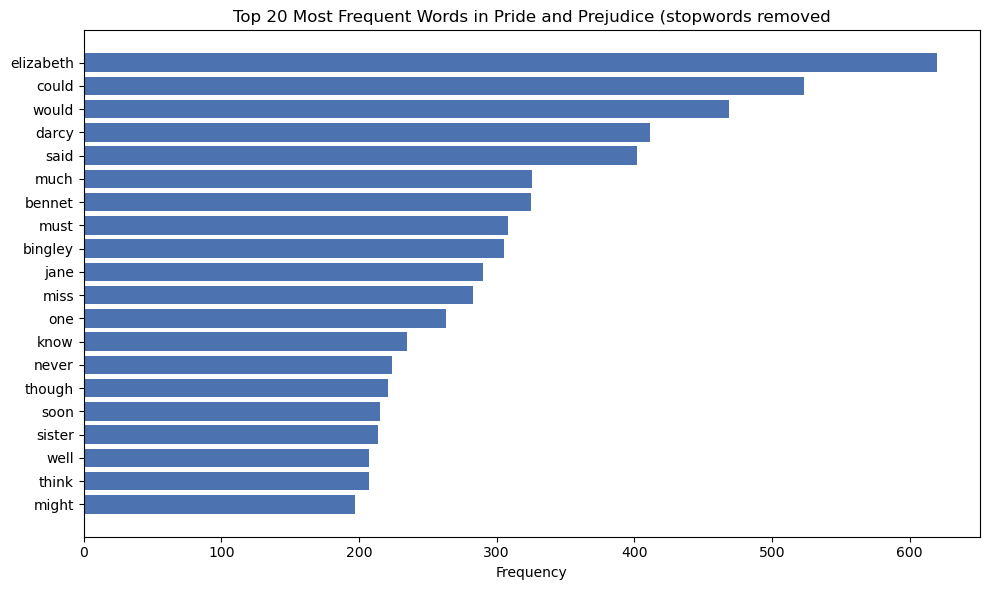

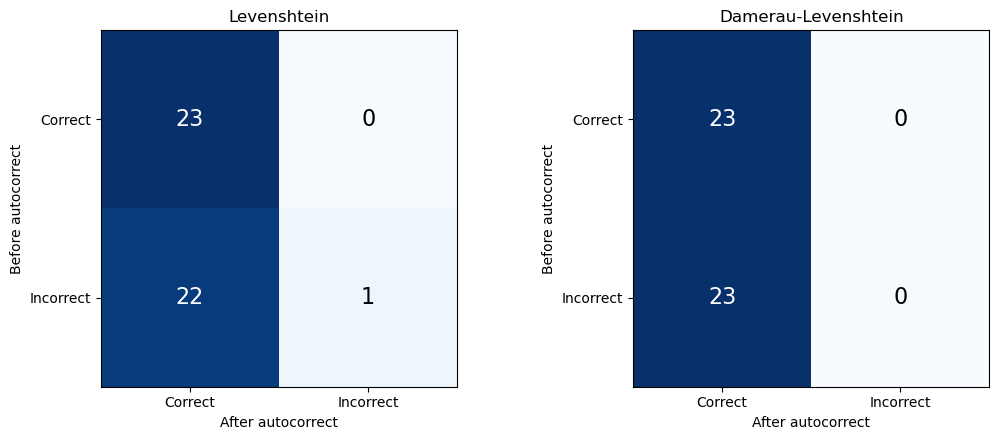

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- 1. Top 20 most frequent words (stopwords removed) ----------
top20 = Counter(tokens_nostop).most_common(20)
words, counts = zip(*top20)

plt.figure(figsize=(10, 6))
plt.barh(words[::-1], counts[::-1], color='#4C72B0')
plt.title('Top 20 Most Frequent Words in Pride and Prejudice (stopwords removed')
plt.xlabel('Frequency')
plt.tight_layout()
plt.show()

# ----------- 2. Autocorrect confusion matrices -------------
def confusion(dist_fn):
    # Rows: state BEFORE (Correct, Incorrect); Columns: state AFTER (Correct, Incorrect)
    m = np.zeros((2, 2), dtype=int)
    for wrong, correct in test_pairs:
        # Before = incorrect (misspelled input)
        out = autocorrect_with(wrong, dist_fn)
        m[1, 0 if out == correct else 1] += 1
        # Before = correct (should be left untouched)
        out2 = autocorrect_with(correct, dist_fn)
        m[0, 0 if out2 == correct else 1] += 1
    return m

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, fn) in zip(axes, [('Levenshtein', levenshtein),
                                 ('Damerau-Levenshtein', damerau)]):
    m = confusion(fn)
    ax.imshow(m, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Correct', 'Incorrect'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Correct', 'Incorrect'])
    ax.set_xlabel('After autocorrect'); ax.set_ylabel('Before autocorrect')
    ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha='center', va='center',
                    color='white' if m[i, j] > m.max() / 2 else 'black', fontsize=16)
plt.tight_layout()
plt.show()

**Result summary.** Autocorrect reached 95.65% accuracy with Levenshtein and 100% with Damerau-Levenshtein, which fixed 'recieve' by treating a letter swap as one edit. Autocorrect reached 20.59% recal@3 with a trigram model and 22.87% with a bigram model. The trigram model did not beat the bigram, a sin of data sparsity in a singel-book corpus.

**Limitations of this implemantation**
1. **Tiny, single-domain corpus.** About 120k words from 1813 novel. The model predicts 'darcy' and 'bennet' after 'mr' but would fail on modern text. Google Keyboard is trained on billions of words and adapts to the individual user.
2. **Dictionary limited to the novel's vocabulary** (about 6,200 words). Autocorrect can only fix words to ones it has seen, so common modern words like 'email' are out of reach.
3. **No context in autocorrect.** It picks the closet word by edit distance and frequency, ignoring the sentence. It can't tell 'their' from 'there'. Production sytems rank candidates withn a language model that considers surrounding words.
4. **Small, hand-made test set.** The 23 misspellings are my own and skew toward single-errors typos. Real typing errors include multi-letter mistakes, phonetic spellings and keyboard-proximity errors. 100% accuracy on 23 words doesn't mean 100% in real uses.
5. **Basic tokenization.** Possessive split into stray tokens ('catherine' + 's'), and puctuation and capitalization are dropped.
6. **Slow search.** Autocorrect compares each input against the whole dictionary, which took several seconds for 23 words. Production systems uses indexed structures such as BK-trees or symmetric delete lookups to answer in milliseconds on-device.
7. **Frequency-onlyprediction.** N-gram counts can't capture meaning or long-range context. Modern keyboards use neutral language models (e.g., LSTM or transformer-based) and also learn from the user's typing history.

**How production systems differ:** neutal models trained on massive data, personalization, keyboard-geometry-aware error models (a slip to a neighboring key is more likely than a random substitution), multilingual support, and on-device optimization for speed and privacy.

**Improvements I would make:** a larger and more varied corpus, smoothing techniques (such as Kneser-Ney or interpolation) to fix the trigram sparsity problem, context-aware candidate ranking for autocorrect, and a bigger, more realistic test set.